In [2]:
import matplotlib.pyplot as plt
from dstools.dynamic_spectrum import DynamicSpectrum, LightCurve
from dstools.plotting import plot_ds, plot_lightcurve
import os
from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from matplotlib.patches import Rectangle
import astropy.constants as c
import astropy.units as u
from scipy.optimize import curve_fit
import lightkurve as lk
from astropy.timeseries import LombScargle
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation
from scipy.signal import find_peaks
import george
from george import kernels
from scipy.optimize import minimize

While we have less data for TYC 8927 than HD 104919, we still do have a clear burst. Let's see if we can figure out some things about this burst.

In [3]:
# List of DS files
vis_path = Path('../visibility_files/')
ds_files = list(vis_path.rglob('*.ds'))

# Choose TYC 8927 dynamic spectra
matches = [p for p in ds_files if "tyc_8927" in str(p)]

In [4]:
matches

[PosixPath('../visibility_files/tyc_8927-1888-1/22333/tyc_8927_22333.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/36208/tyc_8927_36208.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/39406/tyc_8927_39406.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/57060/tyc_8927_57060.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/67961/tyc_8927_67961.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/54101/tyc_8927_54101.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/75575/tyc_8927_75575.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/8678/tyc_8927_8678.ds')]

# Finding the burst

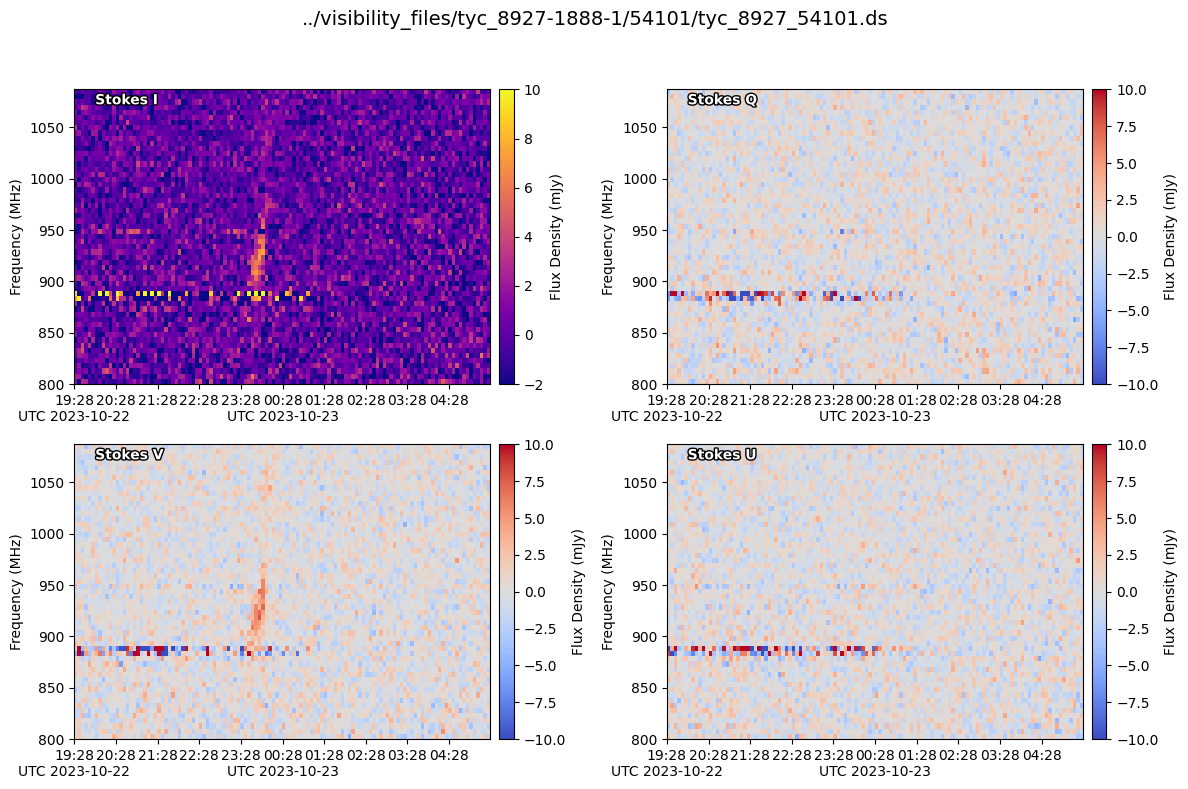

In [5]:
tavg=30
favg=5
ds = DynamicSpectrum(ds_path=matches[5],tavg=tavg, favg=favg)
lc = LightCurve(ds)
cmax_val = 10

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_ds(ds, stokes='I', cmax=cmax_val, imag=False, fig=fig, ax=axes[0, 0])

plot_ds(ds, stokes='Q', cmax=cmax_val, imag=False, fig=fig, ax=axes[0, 1])

plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=axes[1, 0])

plot_ds(ds, stokes='U', cmax=cmax_val, imag=False, fig=fig, ax=axes[1, 1])

fig.suptitle(f'{str(matches[5])}', fontsize=14)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

(<Figure size 800x600 with 1 Axes>, <Axes: ylabel='Flux Density (mJy)'>)

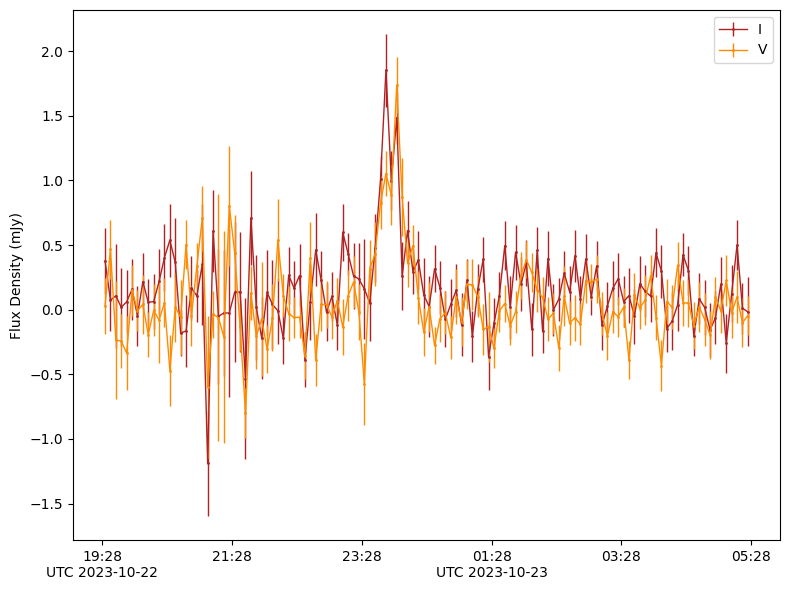

In [8]:
plot_lightcurve(lc, stokes = 'IV')

Before we do any other analysis, we should get rid of our RFI lanes from this data.

In [5]:
def freq_filter(fmin, fmax, ds):
    freq_list = ds.freq #np.linspace(ds.fmin, ds.fmax, len(ds))
    freq_filter1 = ((freq_list > fmin) & (freq_list < fmax))
    ds.data['I'][:, freq_filter1] = np.nan
    ds.data['Q'][:, freq_filter1] = np.nan
    ds.data['U'][:, freq_filter1] = np.nan
    ds.data['V'][:, freq_filter1] = np.nan
    return ds

(850.0, 900.0)

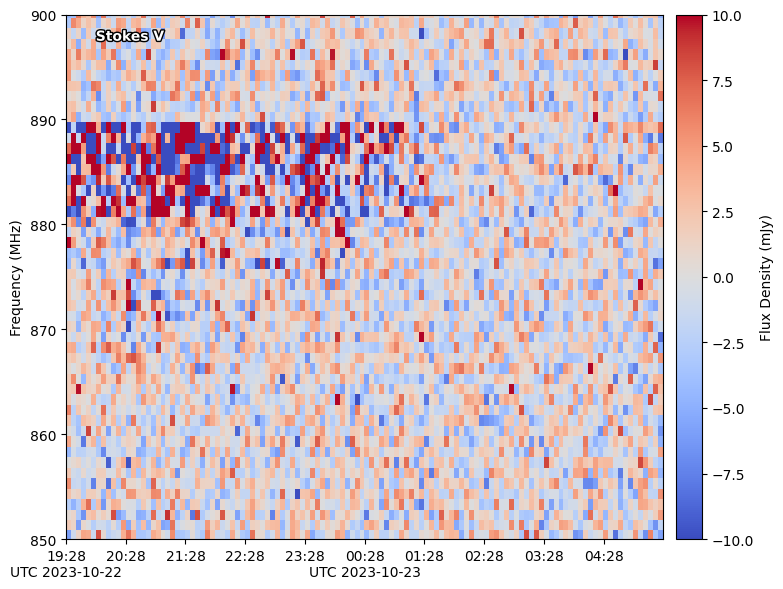

In [6]:
tavg=30
favg=1
ds = DynamicSpectrum(ds_path=matches[5],tavg=tavg, favg=favg)
plot_ds(ds, stokes='V', cmax=cmax_val, imag=False)
plt.ylim(850,900)

In [7]:
freq_filter(880,890, ds)

DynamicSpectrum(ds_path=PosixPath('../visibility_files/tyc_8927-1888-1/54101/tyc_8927_54101.ds'), favg=1, tavg=30, minfreq=None, maxfreq=None, mintime=None, maxtime=None, minuvdist=0, maxuvdist=inf, minuvwave=0, maxuvwave=inf, flag_channels=None, flag_times=None, tunit=Unit("h"), corr_dumptime=0.0028055555555555555, barycentre=False, derotate=False, dedisperse=False, RM=None, RM_reffreq=None, DM=None, DM_reffreq=None, fold=False, period=None, period_offset=0.0, fold_periods=2, phase_bins=None, absolute_times=True, calscans=True, trim=True)

(<Figure size 800x600 with 2 Axes>, <Axes: ylabel='Frequency (MHz)'>)

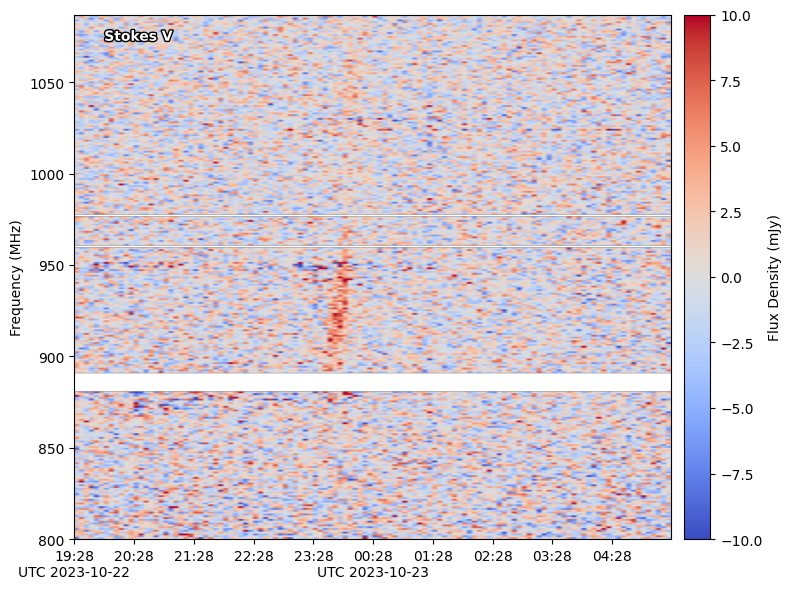

In [8]:
plot_ds(ds, stokes='V', cmax=cmax_val, imag=False)

So now we have a convenient way to remove certain RFI lanes, we can continue with our analysis. Let's just take the maximum lightcurve flux density for now as an underestimate for the burst brightness.

(<Figure size 800x600 with 1 Axes>, <Axes: ylabel='Flux Density (mJy)'>)

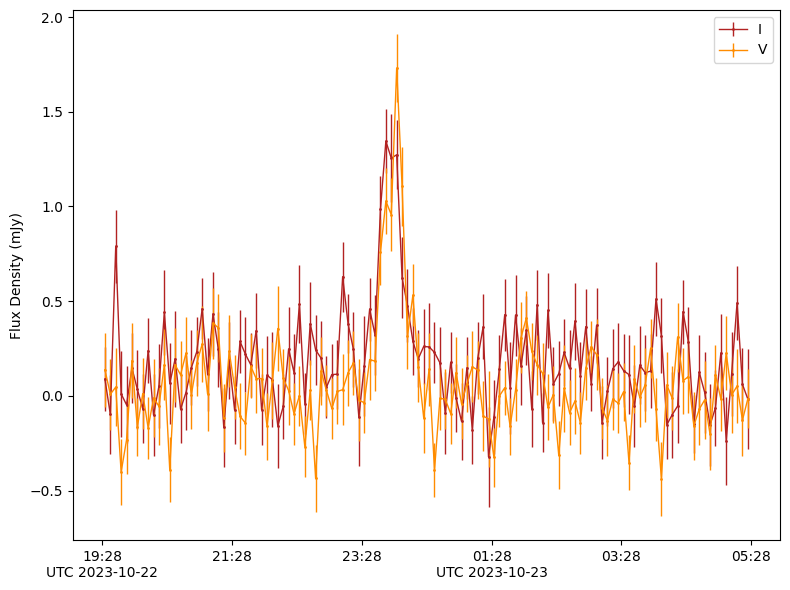

In [9]:
# Smoothing to make the burst apparent
tavg=30
favg=5

# Create the lightcurve from the smoothed+RFI filtered DS
ds = DynamicSpectrum(ds_path=matches[5],tavg=tavg, favg=favg)
freq_filter(880,890, ds)
lc = LightCurve(ds)

# Plot our lightcurve
plot_lightcurve(lc, stokes = 'IV')

Here we can see the burst is ~100% circularly polarised. At the peak, it is greater than 100%, which is non-physical. This is likely a result of poor image subtraction or poor RFI filtering. For now, let's just estimate a peak flux density of 2 mJy.

# Brightness temperature estimate

As before with HD 104919...

In [10]:
nu = 950 * u.MHz
flux = 2 * u.mJy
dist = 	133.523127155304991	 * u.pc

In [11]:
Tb = (c.c**2) / (2 * c.k_B * nu**2) * (flux * dist**2) / (np.pi * c.R_sun**2)

In [12]:
Tb.to(u.K)

<Quantity 8.05250705e+11 K>

So once again on the border of coherent/incoherent based on Tb alone. Remember this is a first order estimate.

# Frequency Drift

In [88]:
f_averages = [5,10,15,20,25]
t_averages = [10,20,30,40,50]

In [89]:
def linear(t, a, b):
    return a * t + b

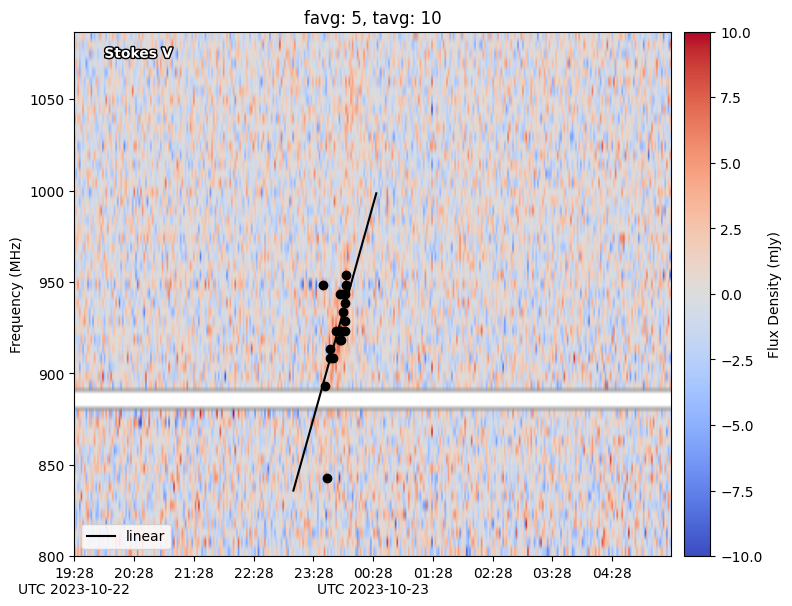

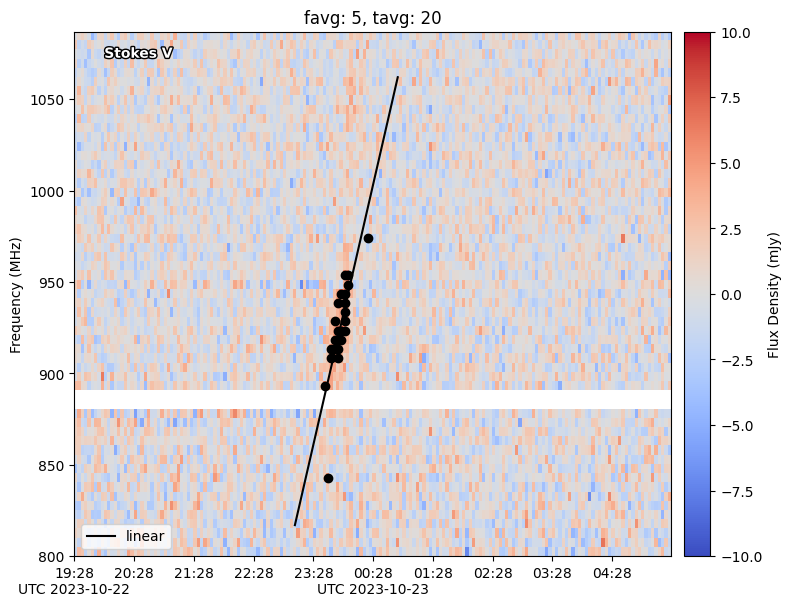

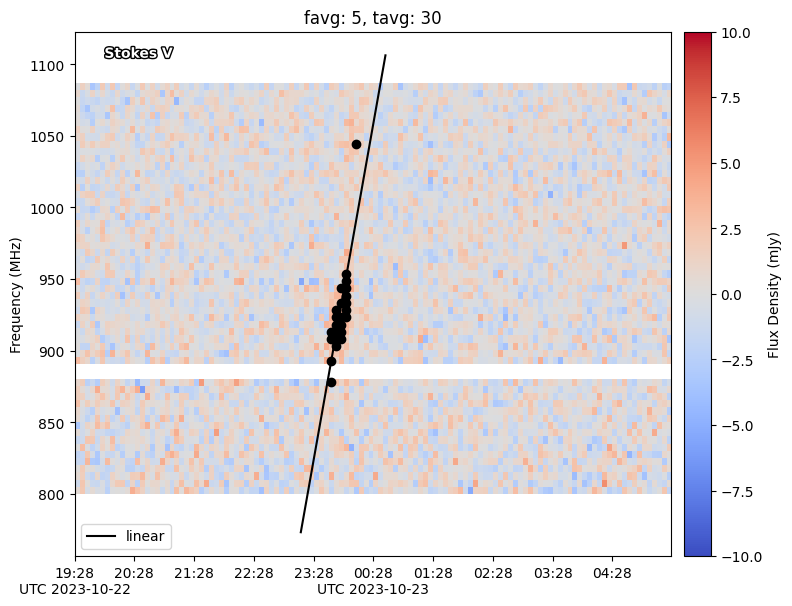

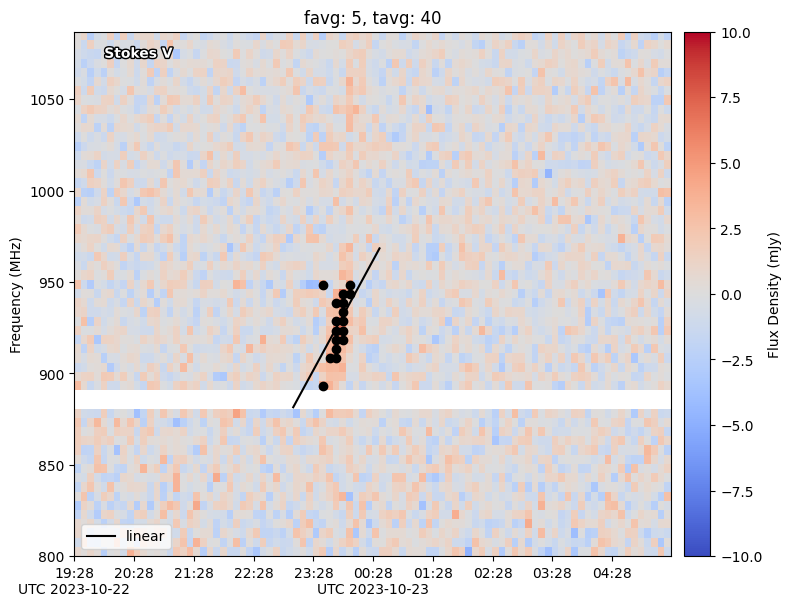

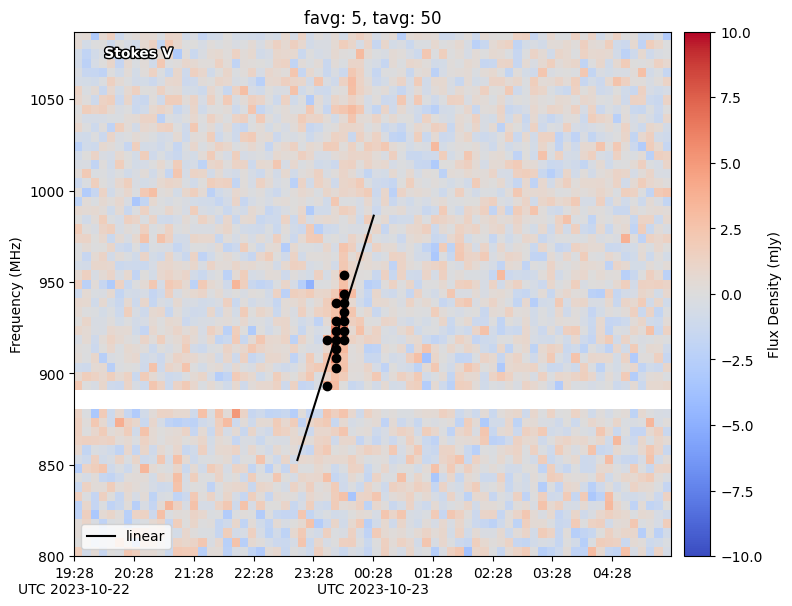

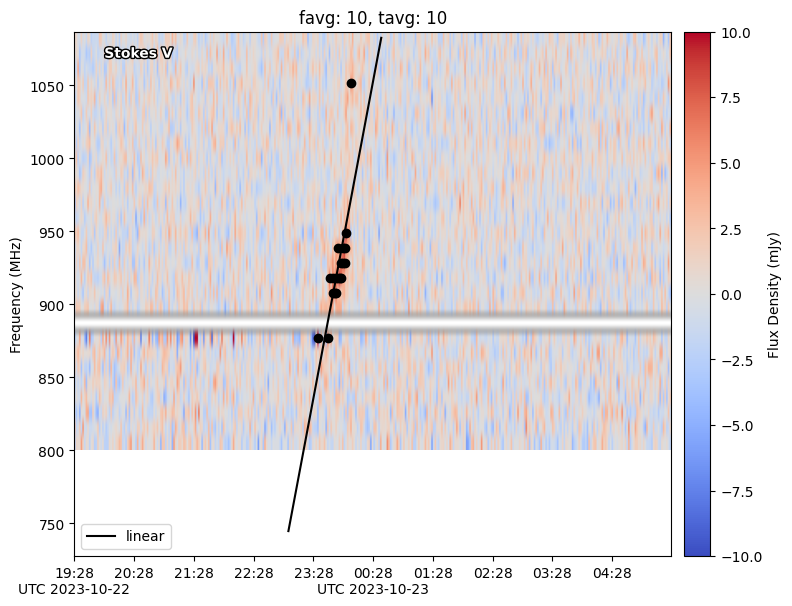

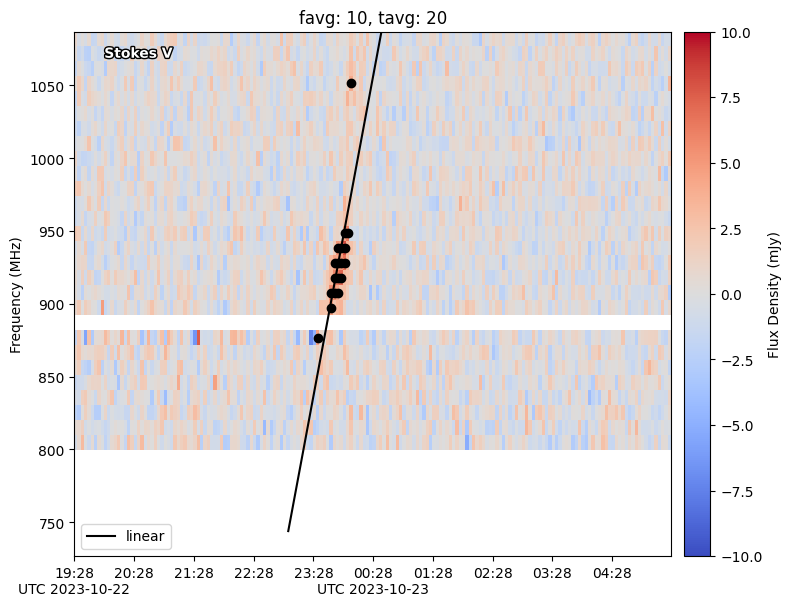

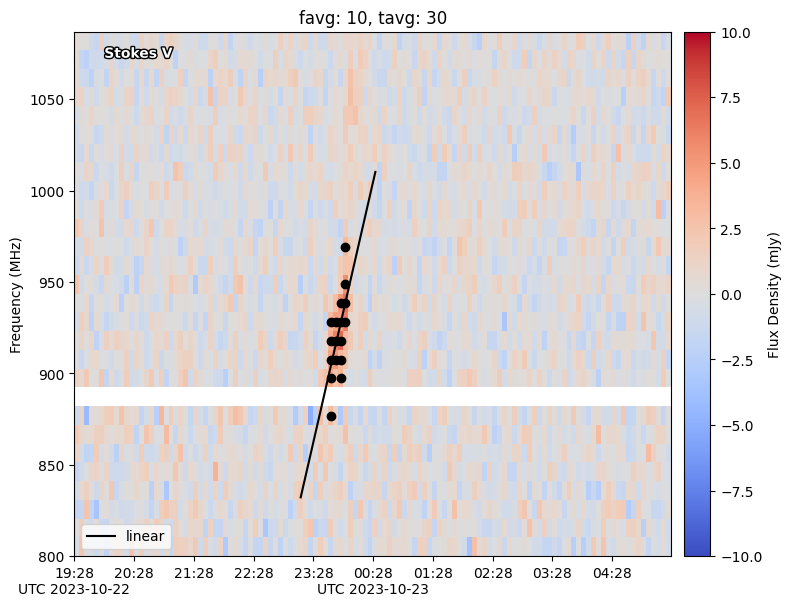

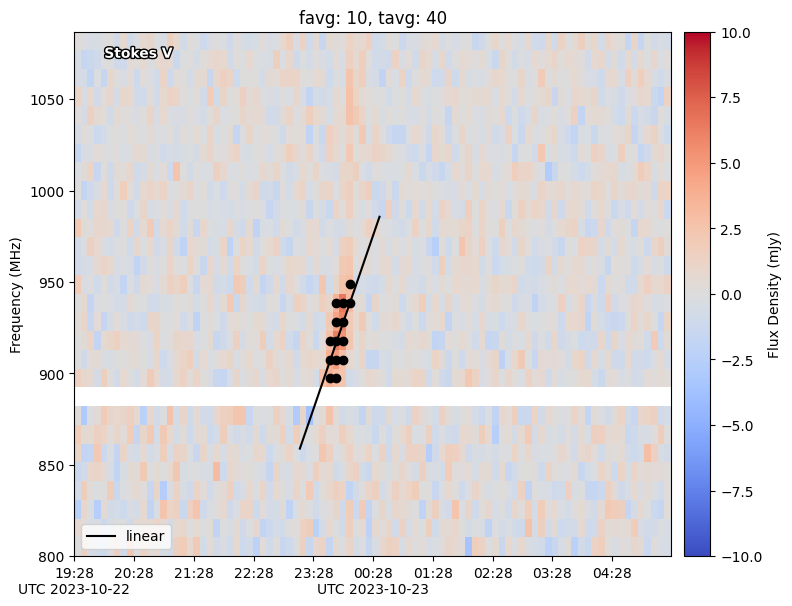

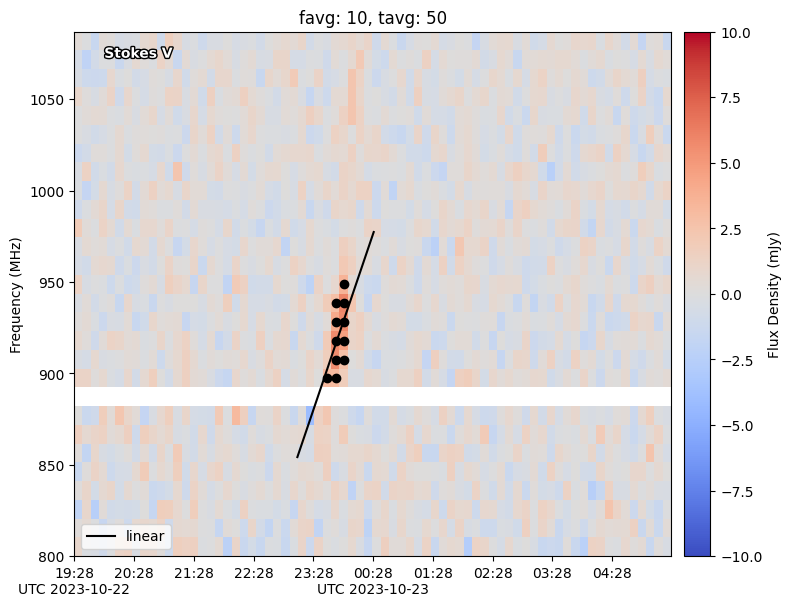

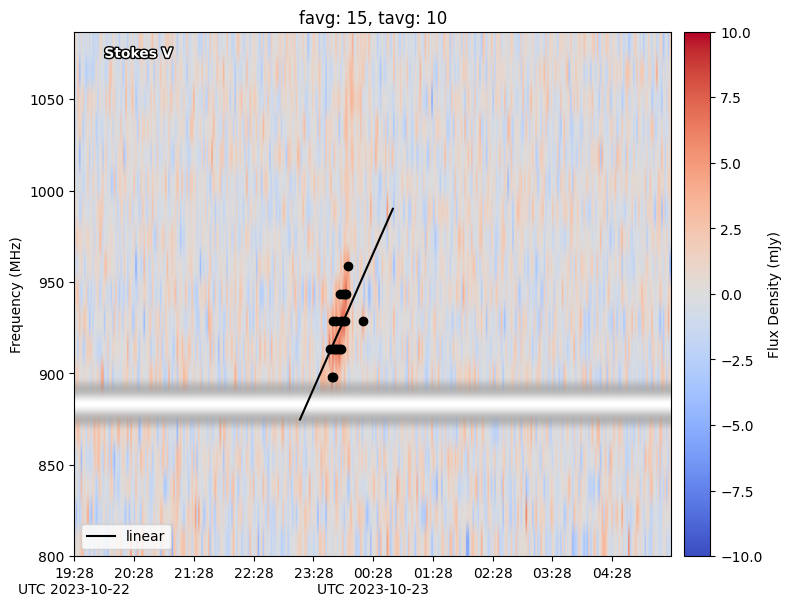

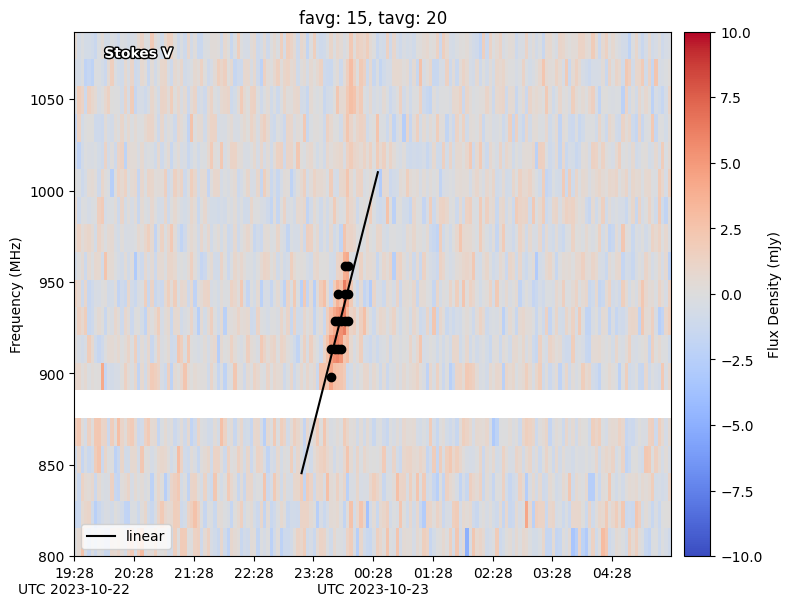

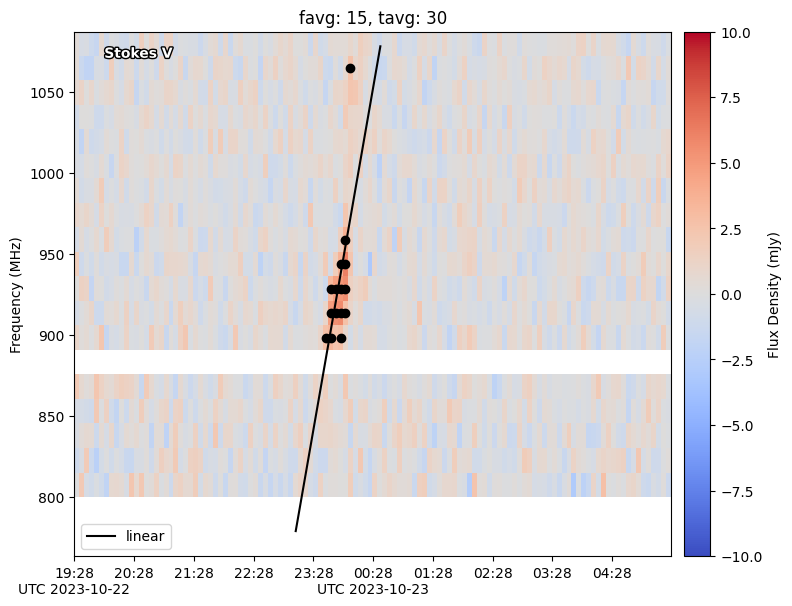

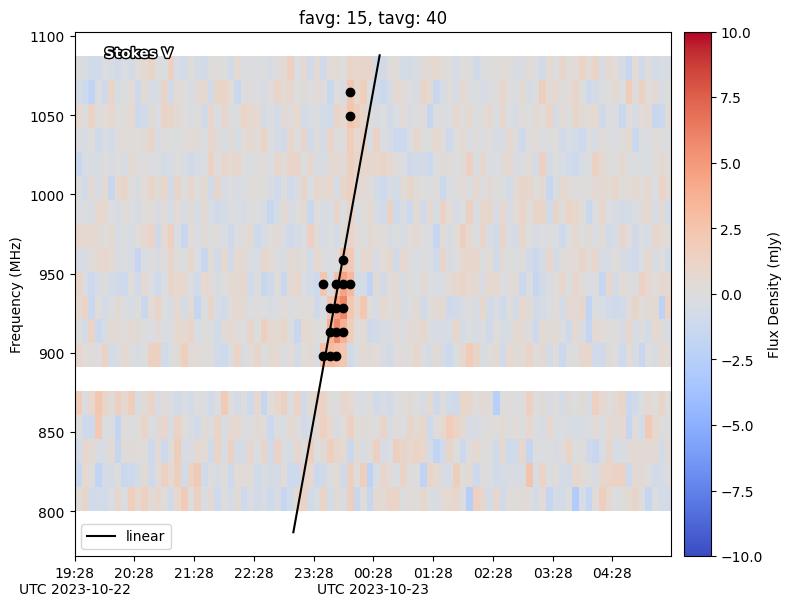

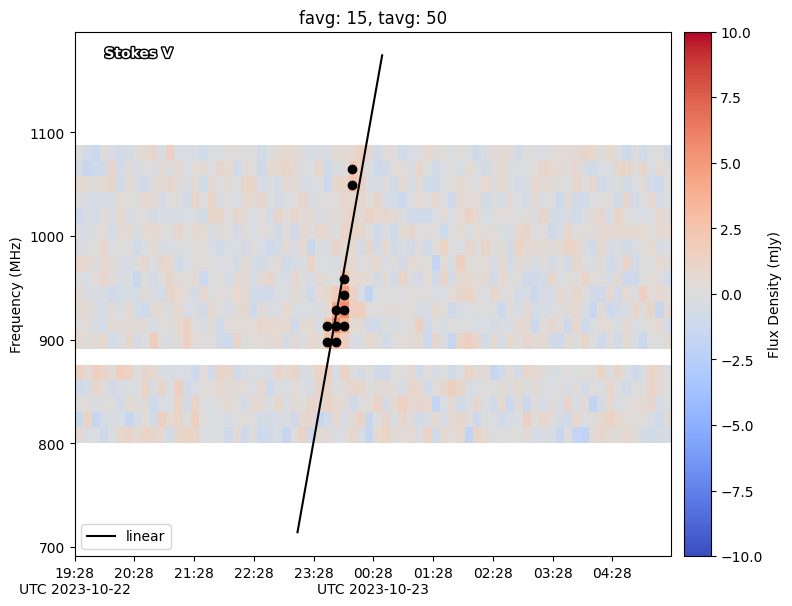

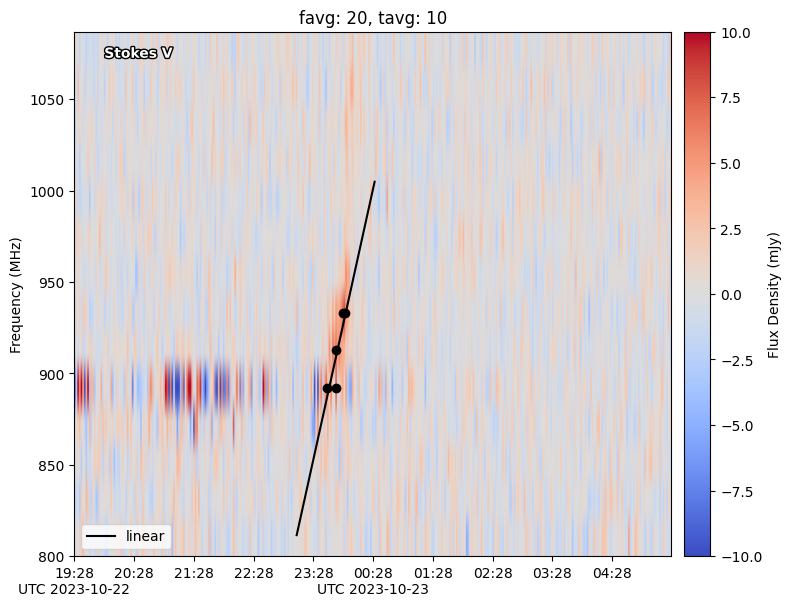

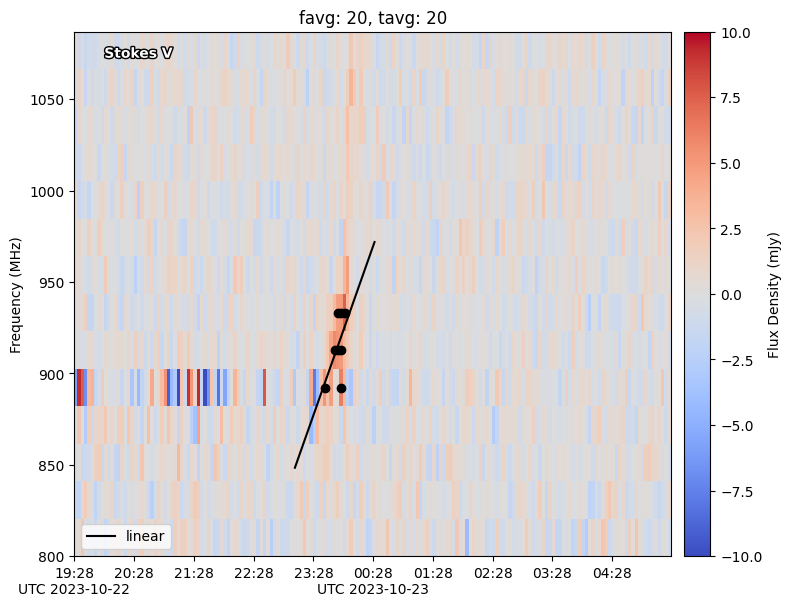

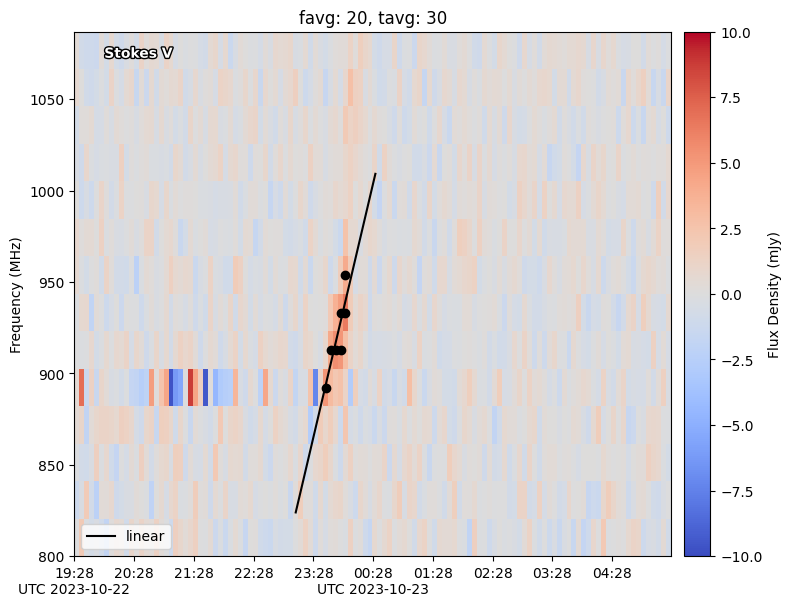

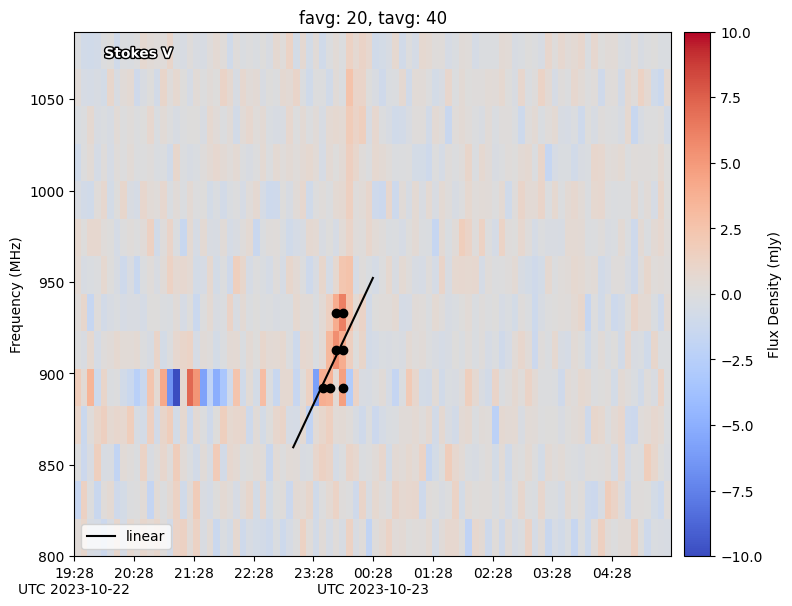

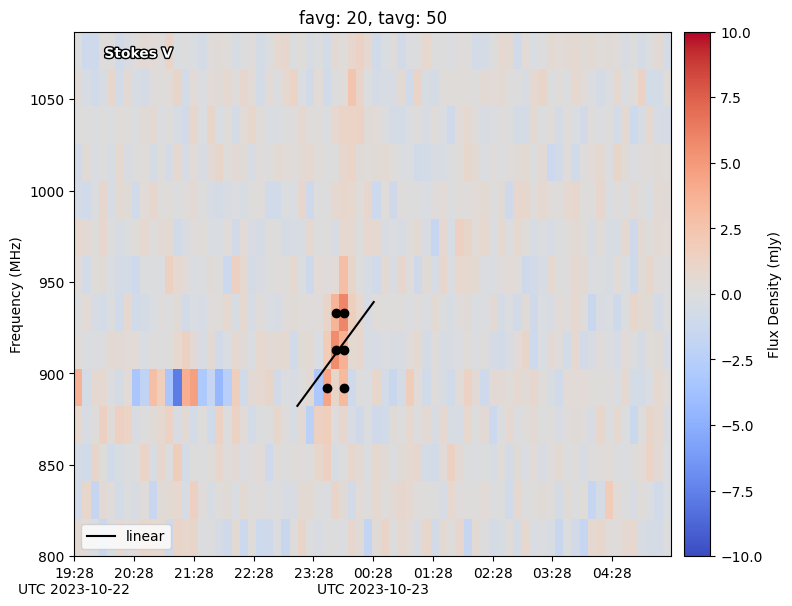

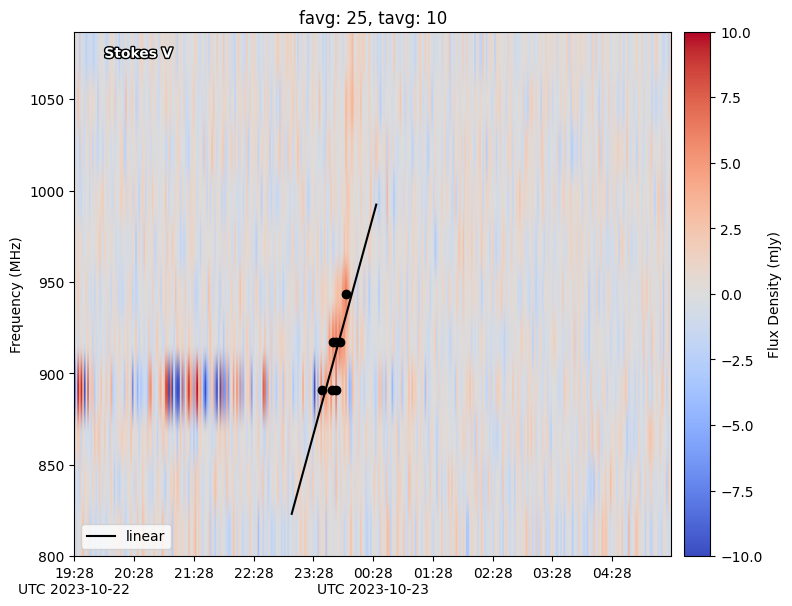

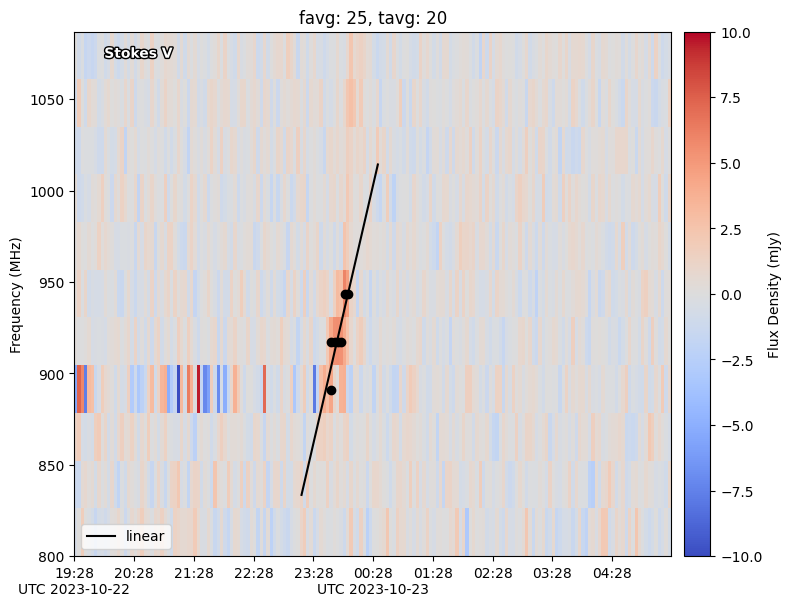

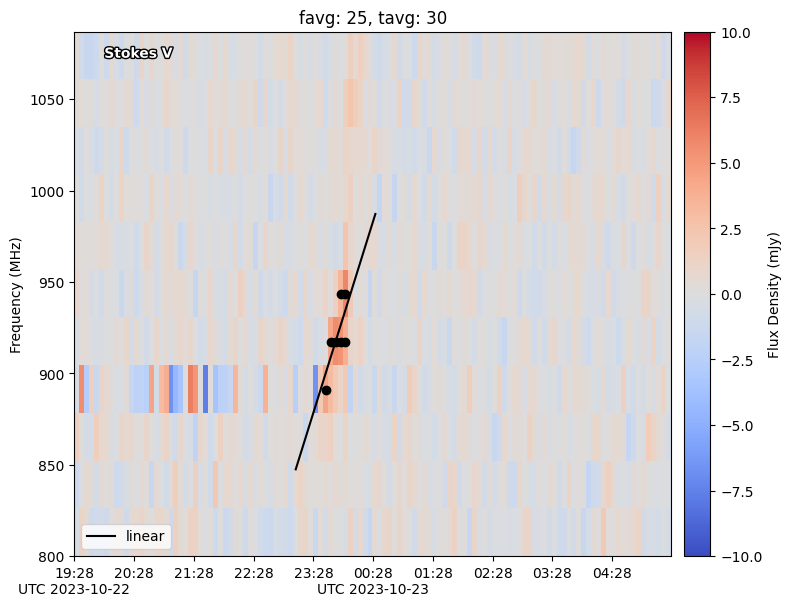

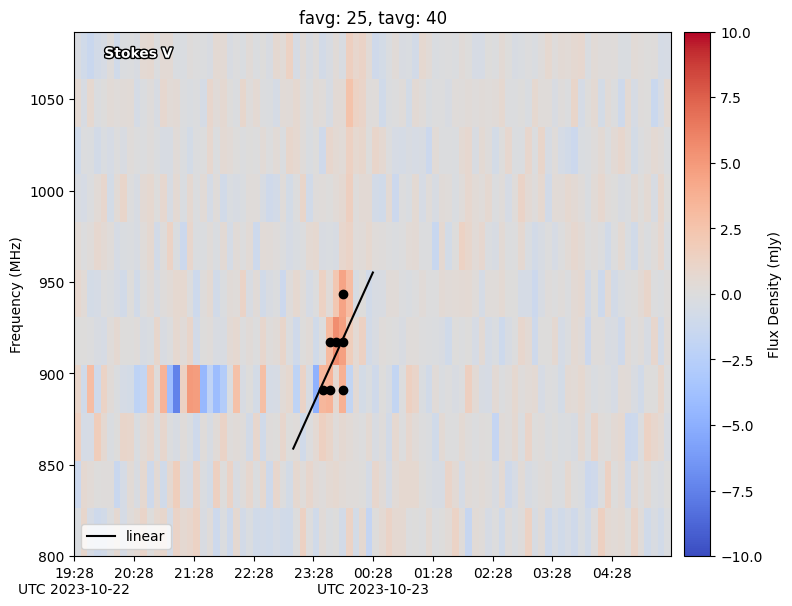

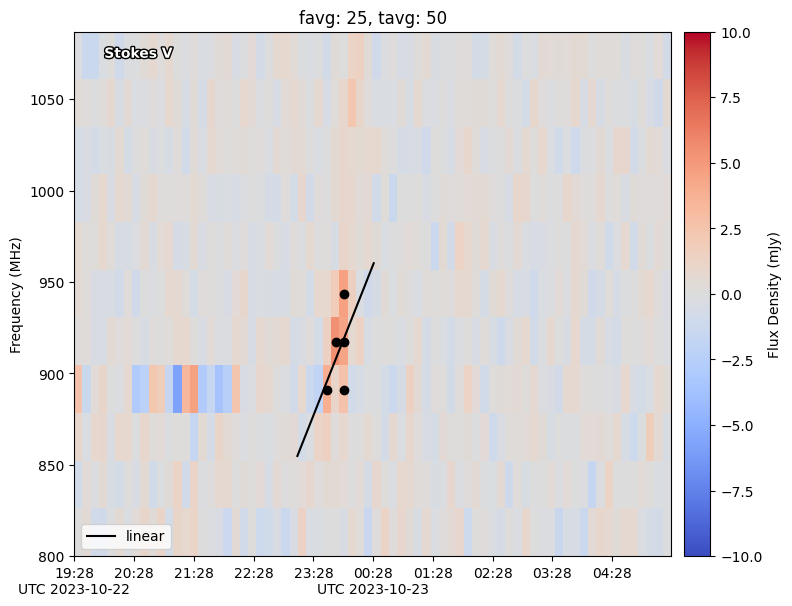

In [93]:
slopes_l, slopes_l_err = [], []

for f in f_averages:
    for t in t_averages:

        # Make the DS
        ds = DynamicSpectrum(ds_path=matches[5],tavg=t, favg=f)
        ds = freq_filter(880,890, ds)
        
        # SNR Mask
        noise_length = int((2/10) * len(ds.time))
        noise = np.nanstd(np.real(ds.data['V'][:noise_length]))
        snr_map = np.real(ds.data['V']) / noise
        mask = snr_map > 3 # One sided

        # Time mask & data formatting
        T, F = np.meshgrid(ds.time, ds.freq, indexing="ij")
        t_vals = T[mask]
        f_vals = F[mask]

        t_mask = (t_vals > 3.5) & (t_vals < 5)

        t_vals = t_vals[t_mask]
        f_vals = f_vals[t_mask]

        # Order our arrays so that curvefit likes us
        order = np.argsort(t_vals)
        t_fit = t_vals[order]
        nu_fit = f_vals[order]

        # Linear model
        popt_l, pcov_l = curve_fit(linear, t_fit, nu_fit)
        lin_slope, lin_intercept = popt_l
        lin_slope_err, lin_intercept_err = np.sqrt(np.diag(pcov_l))
    
        # Save our results
        slopes_l.append(lin_slope)
        slopes_l_err.append(lin_slope_err)

        # Calculate our models
        t_plot = np.linspace(t_fit.min()-0.5, t_fit.max()+0.5, 500) # Interpolate over a smooth grid
        nu_linear = linear(t_plot, *popt_l)

        # Plot our models v data
        plot_ds(ds, stokes='V', cmax=10)
        plt.scatter(t_fit, nu_fit, c = 'black')
        plt.plot(t_plot, nu_linear, c = 'black', label = 'linear')
        plt.legend(loc = 'lower left')
        plt.title(f'favg: {f}, tavg: {t}')
        plt.show()
        plt.close()

(array([4., 5., 4., 6., 0., 2., 3., 0., 0., 1.]),
 array([ 44.47187219,  72.51291309, 100.553954  , 128.5949949 ,
        156.63603581, 184.67707671, 212.71811762, 240.75915852,
        268.80019943, 296.84124033, 324.88228124]),
 <BarContainer object of 10 artists>)

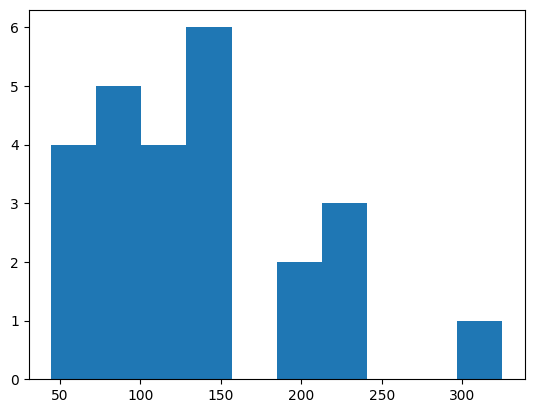

In [95]:
plt.hist(slopes_l)

A lot of these fits are not good, but they are still better than nothing. I think we underestimate more than we overestimate, so let's conservatively say ~200MHz/hr for now as our drift rate. This is much faster than we saw in HD 104919,  but also in the opposite direction. This is not really indicative of plasma emission, so let's assume ECM.

The next part is to figure out WHY this star has an ECM burst. Recall that this was some sort of binary system:

# TESS Counterpart

In [154]:
lc = lk.search_lightcurve('TYC 8927-1888-1', author='QLP').download_all().stitch()

(0.95, 1.05)

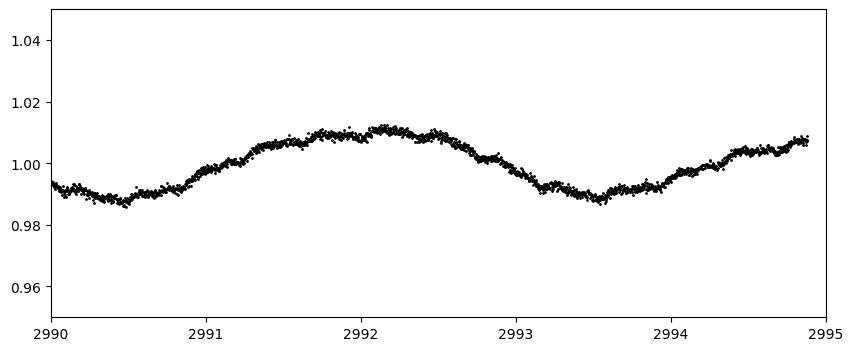

In [161]:
plt.figure(figsize = (10,4))
plt.scatter(lc.time.value, lc.flux.value, c = 'black', s = 1)
plt.xlim(2990,2995)
plt.ylim(0.95,1.05)

This looks like it has 2 periods to it, perhaps a binary period as well as a rotation period?

In [15]:
def calc_lomb_scargle(t, y):

    # remove NaNs
    mask = np.isfinite(t) & np.isfinite(y)
    t = t[mask]
    y = y[mask]

    # remove mean
    y = y - np.mean(y)

    oversample = 10

    tspan = t.max() - t.min()
    df = 1.0 / tspan

    fmin = df
    fmax = 25  # cycles/day

    freq = np.arange(fmin, fmax, df / oversample)

    model = LombScargle(t, y)
    power = model.power(freq)

    # simple amplitude estimate (relative, not absolute physical ppm)
    amp = np.sqrt(power)

    return freq, amp

In [16]:
freq, amp = calc_lomb_scargle(lc.time.value, lc.flux.value)

(0.0, 10.0)

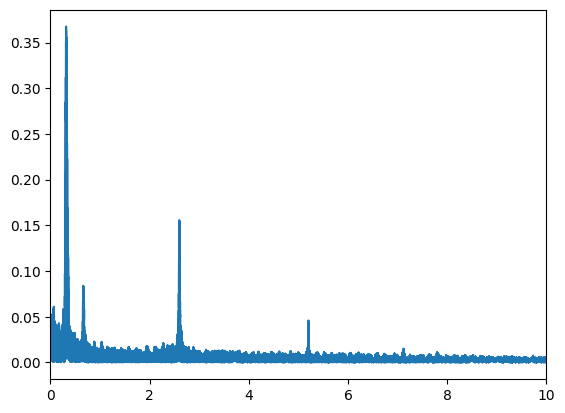

In [17]:
plt.plot(freq, amp)
plt.xlim(0,10)

In [18]:
peaks, _ = find_peaks(amp, distance=1000, prominence = 0.1)

(0.27, 0.37)

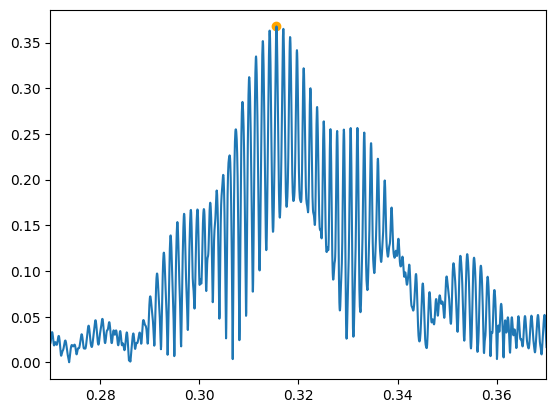

In [19]:
plt.plot(freq, amp)
plt.scatter(freq[peaks], amp[peaks], c = 'orange')
plt.xlim(0.27,0.37)

So now we want to check that these two are not harmonics of eachother

In [20]:
periods = 1 / freq[peaks]
periods

array([3.1688709 , 0.38493201])

So there appears to be a 3 day period as well as a 0.4 day period. Let's assume that these are actual periods that we can fix, and see if we can create a fit to these results.

In [21]:
def double_sinusoid(t, C, A1, phi1, P1, A2, phi2, P2):
    return (
        C
        + A1 * np.sin(2*np.pi*t/P1 + phi1)
        + A2 * np.sin(2*np.pi*t/P2 + phi2)
    )

In [22]:
time = lc.time.value
flux = lc.flux.value
flux_err = lc.flux_err.value

mask = np.isfinite(time) & np.isfinite(flux)

time = time[mask]
flux = flux[mask]
flux_err = flux_err[mask]

In [23]:
p0 = [
    np.median(flux),  # C
    0.1,          # A1
    0,              # phi1
    3.1,            # P1
    0.5,         # A2
    0,              # phi2
    2.7          # P2
]

In [24]:
popt, pcov = curve_fit(
    double_sinusoid,
    time,
    flux,
    p0=p0
)

model = double_sinusoid(time, *popt)
residuals = flux - model

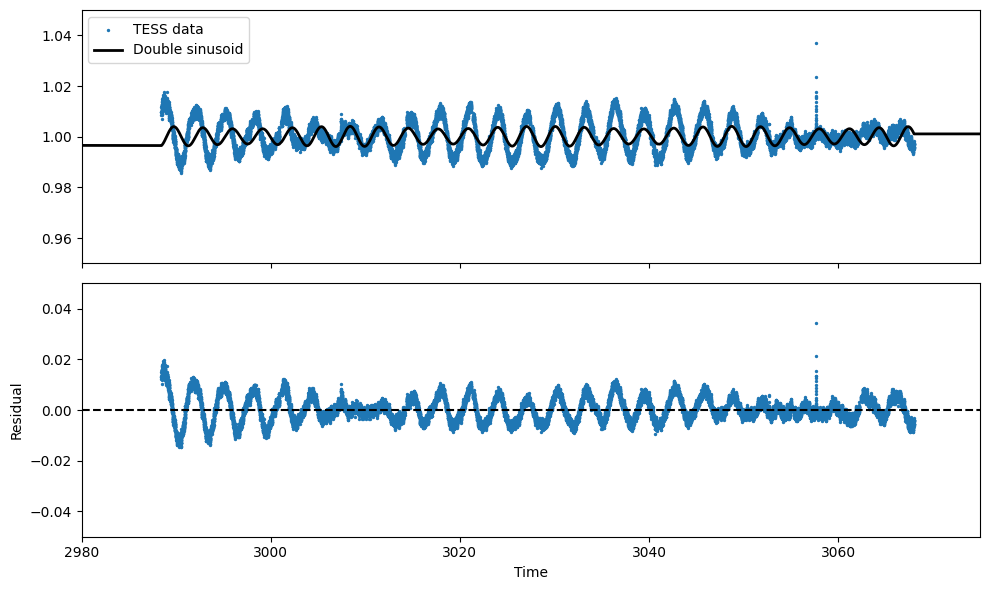

In [25]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax[0].scatter(time, flux, s=2, label='TESS data')
ax[0].plot(time, model, linewidth=2, label='Double sinusoid', c = 'black')
ax[0].legend()
ax[0].set_xlim(2980,3075)
ax[0].set_ylim(0.95,1.05)

ax[1].scatter(time, residuals, s=2)
ax[1].axhline(0, linestyle='--', c = 'black')
ax[1].set_xlabel('Time')
ax[1].set_ylabel('Residual')
ax[1].set_xlim(2980,3075)
ax[1].set_ylim(-0.05, 0.05)

plt.tight_layout()
plt.show()

So we cannot fit to the entire lightcurve. What if we just zoom in on a single sector and try to fit that?

In [26]:
t_mask = (time > 2980) & (time < 3075)

In [27]:
time = time[t_mask]
flux = flux[t_mask]
flux_err = flux_err[t_mask]

In [28]:
p0 = [
    np.median(flux),  # C
    0.1,          # A1
    0,              # phi1
    3.1,            # P1
    0.5,         # A2
    0,              # phi2
    2.7          # P2
]

In [29]:
popt, pcov = curve_fit(
    double_sinusoid,
    time,
    flux,
    p0=p0
)

model = double_sinusoid(time, *popt)
residuals = flux - model

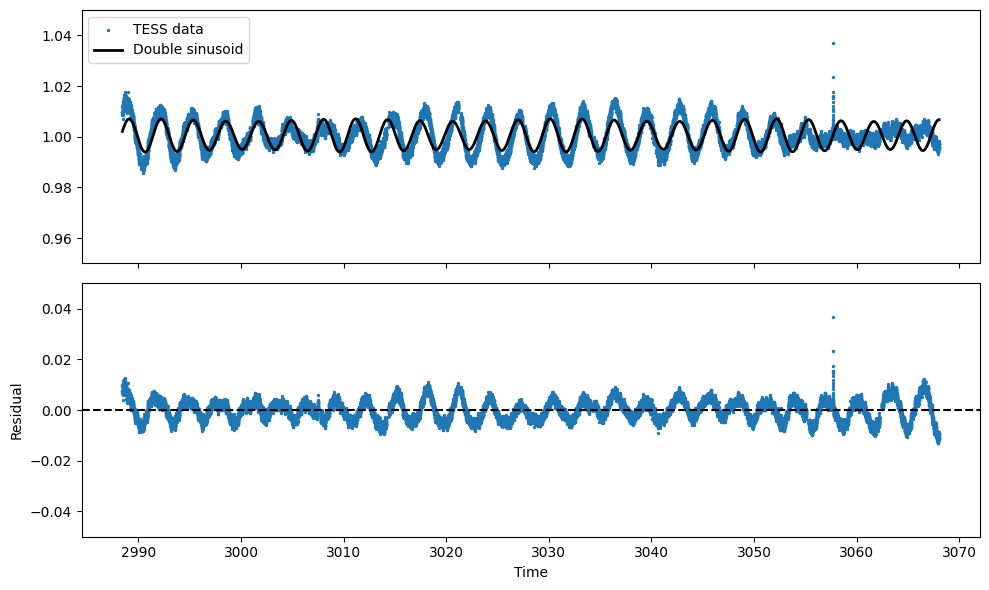

In [30]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax[0].scatter(time, flux, s=2, label='TESS data')
ax[0].plot(time, model, linewidth=2, label='Double sinusoid', c = 'black')
ax[0].legend()
ax[0].set_ylim(0.95,1.05)

ax[1].scatter(time, residuals, s=2)
ax[1].axhline(0, linestyle='--', c = 'black')
ax[1].set_xlabel('Time')
ax[1].set_ylabel('Residual')
ax[1].set_ylim(-0.05, 0.05)

plt.tight_layout()
plt.show()

In [31]:
popt

array([1.00050506e+00, 6.03658904e-03, 1.06843651e+02, 3.15555544e+00,
       5.16677829e-04, 8.35345774e+01, 2.73253313e+00])

So this doesn't appear to work either. Let's see if there is another method. Fit a single sinusoid, look at the residuals, then fit the residuals again?

# Poor man's fourier decomposition

Idk if this will work, what if we just subtract fourier components until we get uncorrelated noise?

In [100]:
def sinusoid(t, C, A, phi, P):
    return C + A * np.sin(2 * np.pi * t / P + phi)

In [101]:
p0 = [
    np.median(flux),  # C
    0.01,          # A
    0.0,           # phi
    3.0            # P
]

bounds = (
    [-np.inf, -np.inf, -2*np.pi, 2.5],
    [ np.inf,  np.inf,  2*np.pi, 3.5]
)

popt, pcov = curve_fit(
    sinusoid,
    time,
    flux,
    p0=p0,
    bounds=bounds,
    maxfev=100000
)

flux_fit = sinusoid(time, *popt)

In [102]:
residuals = flux - flux_fit

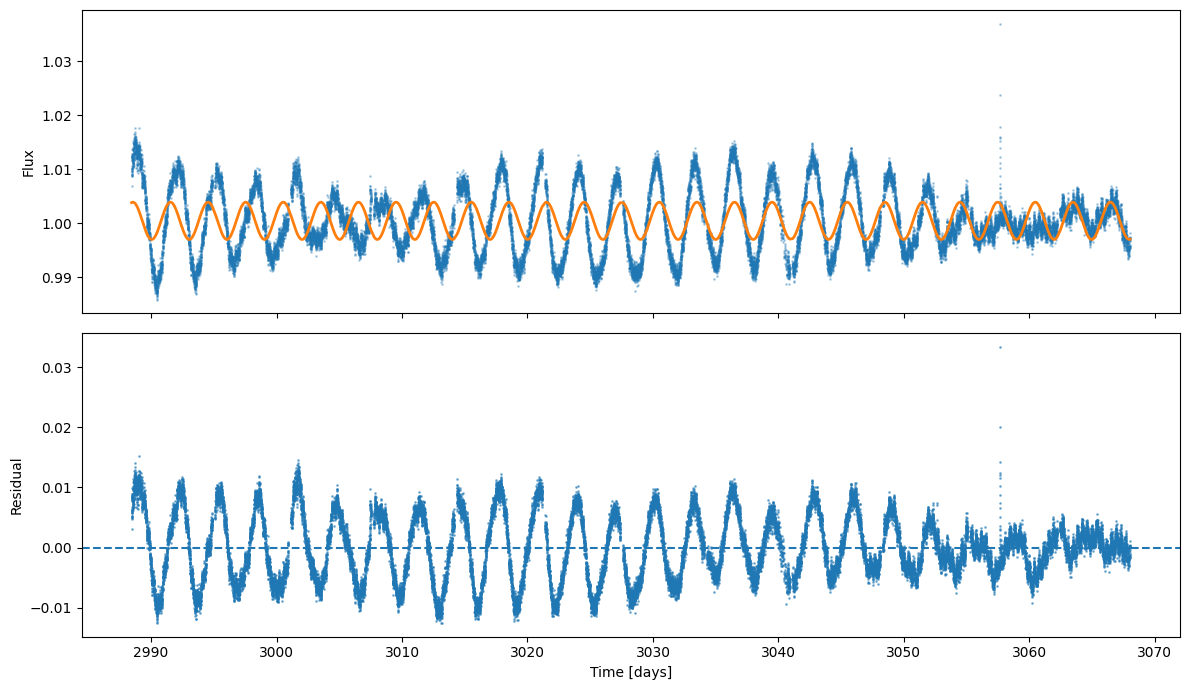

In [103]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax[0].plot(time, flux, ".", ms=2, alpha=0.3)
ax[0].plot(time, flux_fit, lw=2)

ax[0].set_ylabel("Flux")

ax[1].plot(time, residuals, ".", ms=2, alpha=0.5)
ax[1].axhline(0, linestyle="--")

ax[1].set_xlabel("Time [days]")
ax[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

So naturally a single sine wave doesnt fit our data well at all. Let's just repeat this process for another sine wave, but fit the residuals instead of the initial flux:

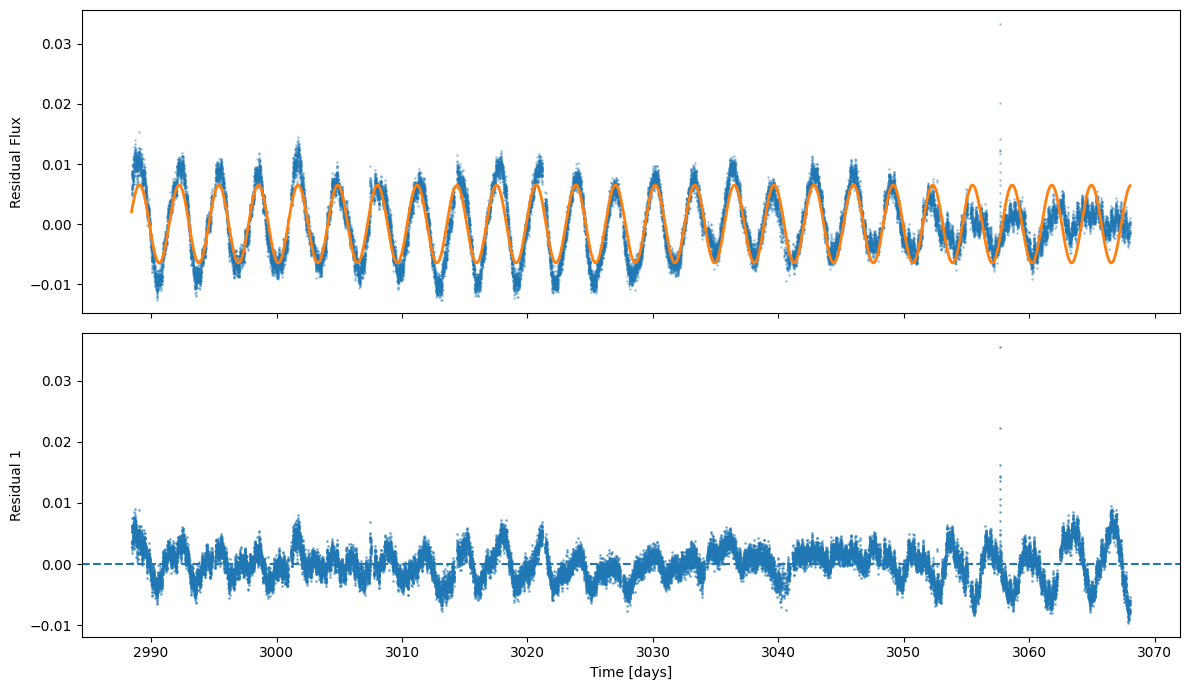

In [107]:
# Find the new dominant period
freq_resid, amp_resid = calc_lomb_scargle(time, residuals)
peak_resid_idx = np.argmax(amp_resid)
peak_resid_freq = freq_resid[peak_resid_idx]
resid_period = 1 / peak_resid_freq

# Fit another sine wave to our residuals
p0_1 = [np.median(residuals), 0.01, 0.0, resid_period]

bounds = (
    [-np.inf, -np.inf, -2*np.pi, 0.8 * resid_period],
    [ np.inf,  np.inf,  2*np.pi, 1.2 * resid_period]
)

popt1, pcov1 = curve_fit(sinusoid, time, residuals, p0=p0_1, bounds=bounds, maxfev=100000)

# Find our new fitted flux
flux_fit_1 = sinusoid(time, *popt1)

# Calculate the second set of residuals
residuals_1 = residuals - flux_fit_1

# Plot it
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax[0].plot(time, residuals, ".", ms=2, alpha=0.3)
ax[0].plot(time, flux_fit_1, lw=2)
ax[0].set_ylabel("Residual Flux")

ax[1].plot(time, residuals_1, ".", ms=2, alpha=0.5)
ax[1].axhline(0, linestyle="--")
ax[1].set_xlabel("Time [days]")
ax[1].set_ylabel("Residual 1")

plt.tight_layout()
plt.show()

And again...

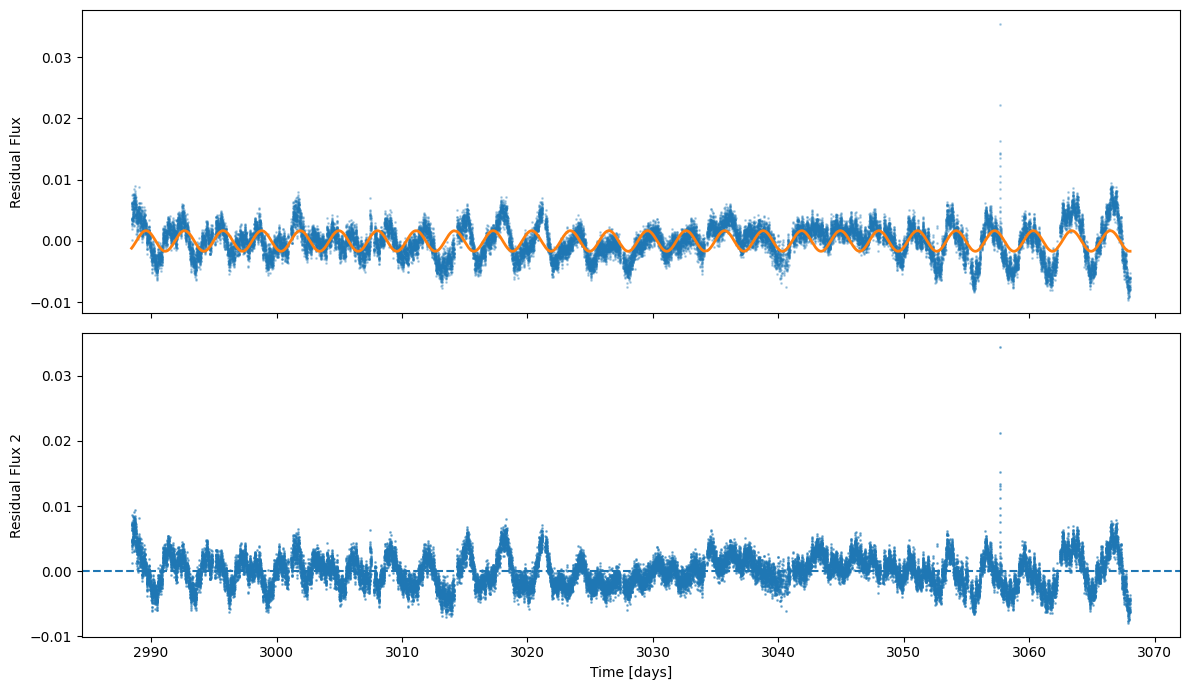

In [109]:
# Find the new dominant period
freq_resid_2, amp_resid_2 = calc_lomb_scargle(time, residuals_1)
peak_resid_2_idx = np.argmax(amp_resid_2)
peak_resid_freq_2 = freq_resid_2[peak_resid_2_idx]
resid_period_2 = 1 / peak_resid_freq_2

# Fit another sine wave to our residuals
p0_2 = [np.median(residuals_1), 0.01, 0.0, resid_period_2]

bounds = (
    [-np.inf, -np.inf, -2*np.pi, 0.8 * resid_period_2],
    [ np.inf,  np.inf,  2*np.pi, 1.2 * resid_period_2]
)

popt2, pcov2 = curve_fit(sinusoid, time, residuals_1, p0=p0_2, bounds=bounds, maxfev=100000)

# Find our new fitted flux
flux_fit_2 = sinusoid(time, *popt2)

# Calculate the second set of residuals
residuals_2 = residuals_1 - flux_fit_2

# Plot it
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax[0].plot(time, residuals_1, ".", ms=2, alpha=0.3)
ax[0].plot(time, flux_fit_2, lw=2)
ax[0].set_ylabel("Residual Flux")

ax[1].plot(time, residuals_2, ".", ms=2, alpha=0.5)
ax[1].axhline(0, linestyle="--")
ax[1].set_xlabel("Time [days]")
ax[1].set_ylabel("Residual Flux 2")

plt.tight_layout()
plt.show()

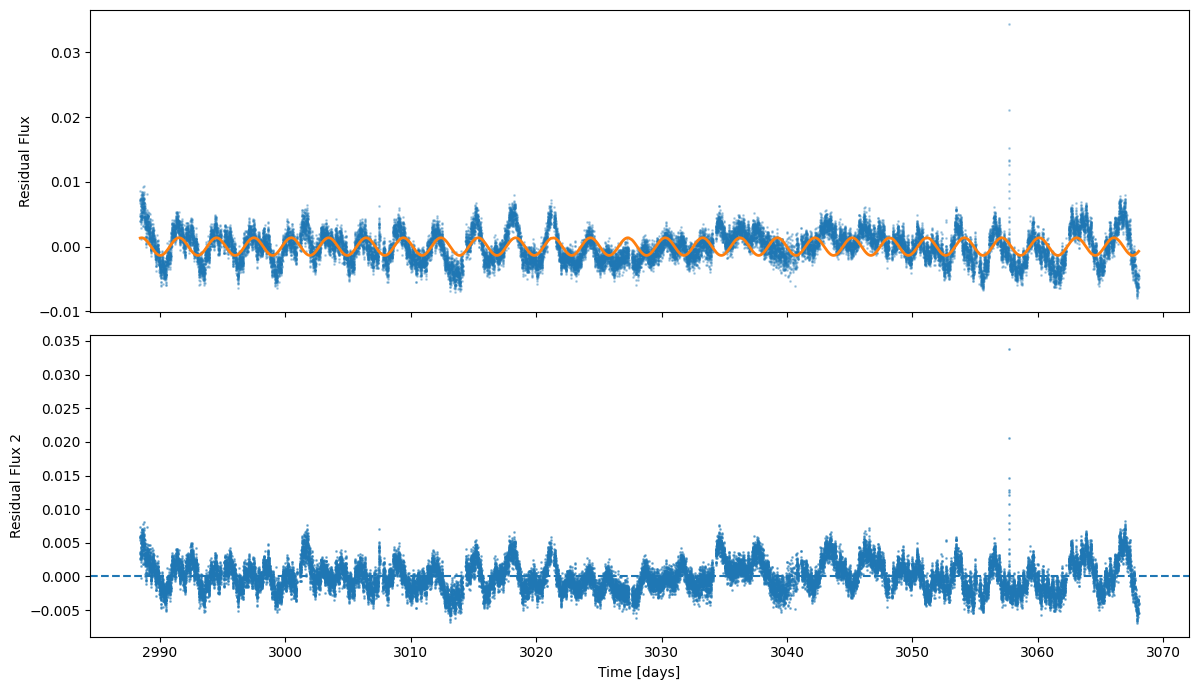

In [110]:
# Find the new dominant period
freq_resid_3, amp_resid_3 = calc_lomb_scargle(time, residuals_2)
peak_resid_3_idx = np.argmax(amp_resid_3)
peak_resid_freq_3 = freq_resid_3[peak_resid_3_idx]
resid_period_3 = 1 / peak_resid_freq_3

# Fit another sine wave to our residuals
p0_3 = [np.median(residuals_2), 0.01, 0.0, resid_period_3]

bounds = (
    [-np.inf, -np.inf, -2*np.pi, 0.8 * resid_period_3],
    [ np.inf,  np.inf,  2*np.pi, 1.2 * resid_period_3]
)

popt3, pcov3 = curve_fit(sinusoid, time, residuals_2, p0=p0_3, bounds=bounds, maxfev=100000)

# Find our new fitted flux
flux_fit_3 = sinusoid(time, *popt3)

# Calculate the second set of residuals
residuals_3 = residuals_2 - flux_fit_3

# Plot it
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax[0].plot(time, residuals_2, ".", ms=2, alpha=0.3)
ax[0].plot(time, flux_fit_3, lw=2)
ax[0].set_ylabel("Residual Flux")

ax[1].plot(time, residuals_3, ".", ms=2, alpha=0.5)
ax[1].axhline(0, linestyle="--")
ax[1].set_xlabel("Time [days]")
ax[1].set_ylabel("Residual Flux 2")

plt.tight_layout()
plt.show()

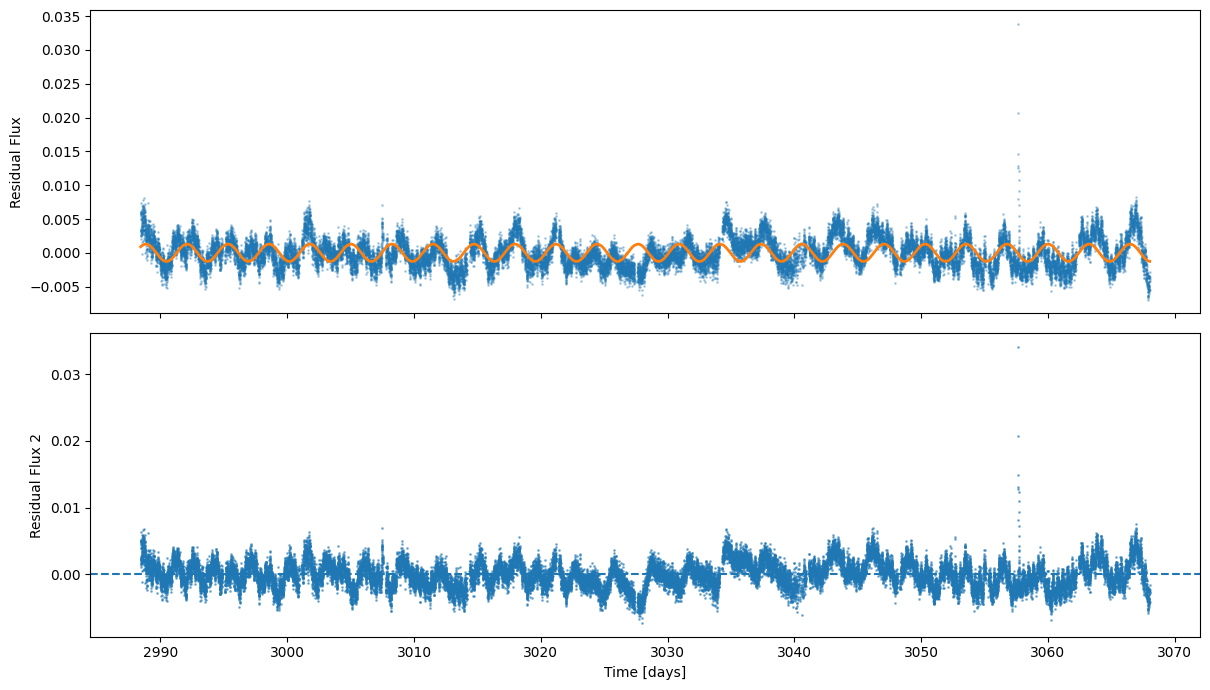

In [127]:
# Find the new dominant period
freq_resid_4, amp_resid_4 = calc_lomb_scargle(time, residuals_3)
peak_resid_4_idx = np.argmax(amp_resid_4)
peak_resid_freq_4 = freq_resid_4[peak_resid_4_idx]
resid_period_4 = 1 / peak_resid_freq_4

# Fit another sine wave to our residuals
p0_4 = [np.median(residuals_3), 0.01, 0.0, resid_period_4]

bounds = (
    [-np.inf, -np.inf, -2*np.pi, 0.8 * resid_period_4],
    [ np.inf,  np.inf,  2*np.pi, 1.2 * resid_period_4]
)

popt4, pcov4 = curve_fit(sinusoid, time, residuals_3, p0=p0_4, bounds=bounds, maxfev=100000)

# Find our new fitted flux
flux_fit_4 = sinusoid(time, *popt4)

# Calculate the second set of residuals
residuals_4 = residuals_3 - flux_fit_4

# Plot it
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax[0].plot(time, residuals_3, ".", ms=2, alpha=0.3)
ax[0].plot(time, flux_fit_4, lw=2)
ax[0].set_ylabel("Residual Flux")

ax[1].plot(time, residuals_4, ".", ms=2, alpha=0.5)
ax[1].axhline(0, linestyle="--")
ax[1].set_xlabel("Time [days]")
ax[1].set_ylabel("Residual Flux 2")

plt.tight_layout()
plt.show()

Let's check just how good this fit is at this point.

In [150]:
C0, A0, phi0, P0 = popt
C1, A1, phi1, P1 = popt1
C2, A2, phi2, P2 = popt2
C3, A3, phi3, P3 = popt3
C4, A4, phi4, P4 = popt4

total_fit = (
    C0 +
    + A0 * np.sin(2*np.pi*time/P0 + phi0)
    + A1 * np.sin(2*np.pi*time/P1 + phi1)
    # + A2 * np.sin(2*np.pi*time/P2 + phi2)
    # + A3 * np.sin(2*np.pi*time/P3 + phi3)
    # + A4 * np.sin(2*np.pi*time/P4 + phi4)
)
total_fit_2 = (
    C0 +
    + A0 * np.sin(2*np.pi*time/P0 + phi0)
    + A1 * np.sin(2*np.pi*time/P1 + phi1)
    + A2 * np.sin(2*np.pi*time/P2 + phi2)
    # + A3 * np.sin(2*np.pi*time/P3 + phi3)
    # + A4 * np.sin(2*np.pi*time/P4 + phi4)
)

total_fit_3 = (
    C0 +
    + A0 * np.sin(2*np.pi*time/P0 + phi0)
    #  + A1 * np.sin(2*np.pi*time/P1 + phi1)
    # + A2 * np.sin(2*np.pi*time/P2 + phi2)
    # + A3 * np.sin(2*np.pi*time/P3 + phi3)
    # + A4 * np.sin(2*np.pi*time/P4 + phi4)
)

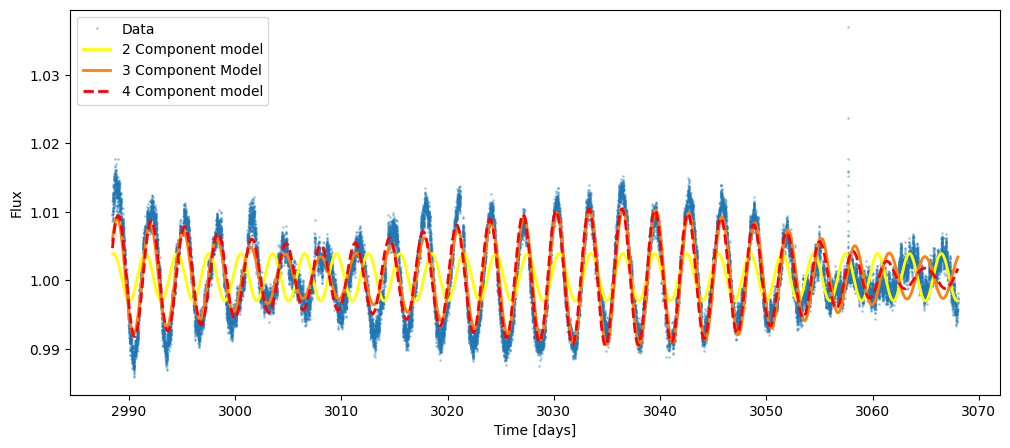

In [162]:
plt.figure(figsize=(12, 5))

plt.plot(time, flux, ".", ms=2, alpha=0.3, label="Data")
plt.plot(time, total_fit_3, lw=2, c = 'yellow', label="2 Component model")
plt.plot(time, total_fit, lw=2, label="3 Component Model")
plt.plot(time, total_fit_2, lw=2, ls = '--', c = 'red', label="4 Component model")

plt.xlabel("Time [days]")
plt.ylabel("Flux")
plt.legend()
plt.show()

Even with 5 components, this isn't a great fit. I think I am just running into a brick wall here. Essentially, we cannot fit this with a few sine waves, we can't just say there are 2 periods.

In [ ]:
# 